# Teoría de Filas en Negocios — Simulación Monte Carlo

En este notebook exploramos escenarios reales de negocios usando **simulación Monte Carlo**.  
Para cada sistema calculamos las métricas operativas, les asignamos una **función de costos** y realizamos **análisis de sensibilidad** variando λ y μ.

---

## Estructura del notebook

| # | Problema | Modelo | Concepto clave |
|---|----------|--------|----------------|
| — | Teoría y fórmulas cerradas | M/M/1, M/M/s | Marco teórico completo |
| — | Funciones de simulación | — | Código canónico comentado línea a línea |
| — | Verificación analítica | M/M/1 | Simulación vs. fórmulas exactas |
| 1 | Banco — cajeros óptimos | M/M/s | Función de costos + s óptimo |
| 2 | Soporte técnico | M/M/s / M/M/s/K | Monte Carlo con costos + capacidad finita |
| 3 | Call center e-commerce | M/M/s | Métricas vs. agentes + sensibilidad |
| 4 | Supermercado online | M/M/s/K | Trade-off capacidad/pérdidas + costos |
| 5 | Soporte con prioridades | M/M/s prioridad | VIP vs. Regular + impacto económico |
| 6 | Procesador de pagos | M/M/s | Picos de demanda + mapa de riesgo |


---
# Marco Teórico — Fórmulas Cerradas

## Notación de Kendall: A/B/s/K

| Símbolo | Significado |
|---------|-------------|
| **A** | Distribución de llegadas (M = Markoviana = Poisson) |
| **B** | Distribución de servicio (M = Markoviana = Exponencial) |
| **s** | Número de servidores en paralelo |
| **K** | Capacidad máxima del sistema (∞ si se omite) |

---

## Parámetros base

| Símbolo | Nombre | Unidad |
|---------|--------|--------|
| $\lambda$ | Tasa de llegada | clientes / unidad de tiempo |
| $\mu$ | Tasa de servicio por servidor | clientes / unidad de tiempo |
| $s$ | Número de servidores | — |
| $\rho = \dfrac{\lambda}{s\,\mu}$ | Factor de utilización | — (debe ser < 1) |

---

## Métricas operativas

| Métrica | Nombre | Descripción |
|---------|--------|-------------|
| $L$ | Clientes en el sistema | Cola + en servicio |
| $L_q$ | Clientes en cola | Solo esperando |
| $L_s$ | Clientes en servicio | Solo siendo atendidos |
| $W$ | Tiempo en el sistema | Espera + servicio |
| $W_q$ | Tiempo en cola | Solo esperando |
| $W_s$ | Tiempo en servicio | Solo siendo atendido |

**Ley de Little** — conecta todas las métricas entre sí:
$$L = \lambda\,W \qquad L_q = \lambda\,W_q \qquad L_s = \lambda\,W_s$$

---

## Fórmulas cerradas: modelo M/M/1

Válidas cuando $s = 1$ y $\rho < 1$:

$$L_s = \rho \qquad L_q = \frac{\rho^2}{1-\rho} \qquad L = \frac{\rho}{1-\rho}$$

$$W_s = \frac{1}{\mu} \qquad W_q = \frac{\rho}{\mu(1-\rho)} \qquad W = \frac{1}{\mu - \lambda}$$

---

## Fórmulas cerradas: modelo M/M/s

Para $s > 1$ servidores en paralelo y $\rho = \lambda/(s\mu) < 1$:

**Probabilidad de sistema vacío:**
$$P_0 = \left[\sum_{n=0}^{s-1} \frac{(s\rho)^n}{n!} + \frac{(s\rho)^s}{s!}\cdot\frac{1}{1-\rho}\right]^{-1}$$

**Clientes en cola:**
$$L_q = P_0 \cdot \frac{(s\rho)^s \,\rho}{s!\,(1-\rho)^2}$$

**Resto de métricas** vía Ley de Little:
$$W_q = \frac{L_q}{\lambda} \qquad W_s = \frac{1}{\mu} \qquad W = W_q + W_s \qquad L = \lambda\,W$$

---

## Función de costos general

$$C(s) = c_{\text{espera}} \cdot L_q(s) + c_{\text{servidor}} \cdot s$$

- $c_{\text{espera}}$: costo por cliente-unidad de tiempo en cola (insatisfacción, pérdida de negocio)  
- $c_{\text{servidor}}$: costo por servidor-unidad de tiempo (salario, infraestructura)

En modelos M/M/s/K se agrega el **costo de rechazo**:
$$C(s,K) = c_{\text{espera}} \cdot L_q + c_{\text{servidor}} \cdot s + c_{\text{rechazo}} \cdot \lambda_{\text{perdida}}$$

donde $\lambda_{\text{perdida}} = \text{tasa\_pérdida} \times \lambda$ es el flujo de clientes rechazados por unidad de tiempo.

---

## ¿Por qué simulación Monte Carlo y no solo fórmulas?

| Capacidad | Fórmulas cerradas | Monte Carlo |
|-----------|:-----------------:|:-----------:|
| M/M/1, M/M/s estándar | ✔ exacto | ✔ aproximado |
| Capacidad finita M/M/s/K | ✔ (complicado) | ✔ directo |
| Prioridades entre grupos | ✗ | ✔ |
| Distribución completa del costo | ✗ | ✔ |
| Análisis de riesgo (percentiles) | ✗ | ✔ |
| Parámetros que cambian en el tiempo | ✗ | ✔ |

Las fórmulas cerradas dan la respuesta exacta en casos simples.  
Monte Carlo permite extender el análisis a cualquier escenario real.


---
## Importaciones

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

np.random.seed(42)  # fijamos la semilla para reproducibilidad

print("Librerías cargadas ✔")


Librerías cargadas ✔


---
## Funciones de simulación — código canónico

Estas son las dos funciones que usamos en todos los problemas.  
Cada línea importante está comentada para que puedas seguir la lógica.


In [12]:
# ════════════════════════════════════════════════════════════════════════════
#  FUNCIÓN 1: simular_mms  —  Sistema M/M/s (capacidad infinita)
# ════════════════════════════════════════════════════════════════════════════
def simular_mms(lam, mu, s, n_pasos, n_rep=500,
                costo_espera=0, costo_servidor=0):
    """
    Simula un sistema M/M/s por Monte Carlo.

    Idea: dividimos el tiempo en pequeños pasos discretos.
    En cada paso ocurren dos eventos en secuencia:
      1) Llegan clientes nuevos  (proceso Poisson con tasa lambda)
      2) Se atienden clientes    (proceso Poisson con tasa s*mu, limitado por los disponibles)

    Parámetros:
    -----------
    lam            : tasa de llegada (clientes / paso)
    mu             : tasa de servicio por servidor (clientes / paso)
    s              : número de servidores en paralelo
    n_pasos        : duración de cada réplica (cantidad de pasos simulados)
    n_rep          : número de réplicas Monte Carlo (más réplicas = más precisión)
    costo_espera   : costo por cliente-paso en cola   ($/cliente/paso)
    costo_servidor : costo fijo por servidor por paso ($/servidor/paso)

    Retorna:
    --------
    Diccionario con L, L_q, L_s, W, W_q, W_s, costo_total y las series temporales.
    """

    # ── Validación de estabilidad ────────────────────────────────────────────
    rho = lam / (s * mu)                    # factor de utilización del sistema
    if rho >= 1:                            # si rho >= 1, la cola crece sin límite
        print(f"⚠️  SISTEMA INESTABLE: ρ = {rho:.2f} ≥ 1  (λ={lam}, s={s}, μ={mu})")
        print("    Las métricas no tienen sentido en estado estacionario.")
        return None                         # devolvemos None para que el código que llama lo detecte

    # ── Arrays para acumular resultados de todas las réplicas ────────────────
    todas_Lq    = []                        # L_q de cada réplica (promedio sobre pasos)
    todas_Ls    = []                        # L_s de cada réplica
    todas_costo = []                        # costo total de cada réplica
    all_colas   = np.zeros((n_rep, n_pasos))# historial completo de la cola (para gráficos)
    all_att     = np.zeros((n_rep, n_pasos))# historial completo de atendidos

    # ── Bucle de réplicas Monte Carlo ────────────────────────────────────────
    for i in range(n_rep):

        cola    = 0                         # estado inicial: sistema vacío
        hist_Lq = np.zeros(n_pasos)         # historial de cola en esta réplica
        hist_Ls = np.zeros(n_pasos)         # historial de en-servicio en esta réplica

        # ── Bucle de pasos (simulación discreta en el tiempo) ────────────────
        for t in range(n_pasos):

            # EVENTO 1 — Llegadas
            # Sorteamos cuántos clientes llegan en este paso
            # np.random.poisson(lam) genera un número aleatorio de una distribución
            # Poisson con media lam: modela llegadas aleatorias e independientes
            cola += np.random.poisson(lam)

            # EVENTO 2 — Atenciones
            # Sorteamos cuántos clientes podrían atenderse (capacidad del sistema)
            # s servidores trabajando en paralelo, cada uno con tasa mu
            capacidad = np.random.poisson(s * mu)

            # No podemos atender más de los que hay en la cola
            atendidos = min(cola, capacidad)
            cola     -= atendidos           # los atendidos salen del sistema

            # REGISTRO del estado al final de este paso
            hist_Lq[t] = cola               # cuántos quedaron esperando
            hist_Ls[t] = min(atendidos, s)  # cuántos están siendo atendidos (máx = s)

        # Guardamos el historial completo para poder graficarlo después
        all_colas[i] = hist_Lq
        all_att[i]   = hist_Ls

        # ── Burn-in: descartamos el 20% inicial ──────────────────────────────
        # Los primeros pasos están sesgados porque el sistema arranca vacío.
        # Necesitamos que el sistema llegue al "estado estacionario" antes de medir.
        # Descartamos el 20% inicial como precaución (ver celda de verificación).
        burn   = n_pasos // 5
        Lq_rep = hist_Lq[burn:].mean()      # L_q promedio en estado estacionario
        Ls_rep = hist_Ls[burn:].mean()      # L_s promedio en estado estacionario

        todas_Lq.append(Lq_rep)
        todas_Ls.append(Ls_rep)
        # Costo de esta réplica: espera + personal
        todas_costo.append(costo_espera * Lq_rep + costo_servidor * s)

    # ── Promedios sobre todas las réplicas ───────────────────────────────────
    Lq = np.mean(todas_Lq)                  # promedio de L_q entre réplicas
    Ls = np.mean(todas_Ls)
    L  = Lq + Ls                            # L = L_q + L_s  (siempre)

    # Ley de Little: W = L / lambda  (aplica a cada componente)
    W  = L  / lam
    Wq = Lq / lam
    Ws = Ls / lam

    return {
        "L": L, "Lq": Lq, "Ls": Ls,
        "W": W, "Wq": Wq, "Ws": Ws,
        "rho": rho,
        "costo_total": np.mean(todas_costo),
        "all_colas":   all_colas,           # shape: (n_rep, n_pasos)
        "all_att":     all_att,
        "todas_costo": np.array(todas_costo),
    }


# ════════════════════════════════════════════════════════════════════════════
#  FUNCIÓN 2: simular_mmsk  —  Sistema M/M/s/K (capacidad máxima K)
# ════════════════════════════════════════════════════════════════════════════
def simular_mmsk(lam, mu, s, K, n_pasos, n_rep=500,
                 costo_espera=0, costo_servidor=0, costo_perdida=0):
    """
    Simula un sistema M/M/s/K por Monte Carlo.

    Igual que simular_mms pero con una capacidad máxima K:
    los clientes que llegan cuando el sistema está lleno se pierden (o se redirigen).

    Parámetros adicionales:
    -----------------------
    K             : capacidad máxima del sistema = cola + en servicio
    costo_perdida : costo por cliente rechazado por paso ($/cliente-rechazado/paso)
                    ⚠️  Este costo se multiplica por lambda_perdida = tasa_perdida * lam
                        (clientes rechazados por paso), NO por el conteo acumulado de la réplica.
    """

    todas_Lq       = []
    todas_Ls       = []
    todas_costo    = []
    todas_perdidos = []                     # tasa de pérdida de cada réplica

    for _ in range(n_rep):

        cola         = 0                    # sistema empieza vacío
        perdidos_rep = 0                    # conteo de rechazados en esta réplica
        llegadas_rep = 0                    # conteo total de llegadas en esta réplica
        hist_Lq      = np.zeros(n_pasos)
        hist_Ls      = np.zeros(n_pasos)

        for t in range(n_pasos):

            # EVENTO 1 — Llegadas
            nuevos        = np.random.poisson(lam)
            llegadas_rep += nuevos          # acumulamos para calcular la tasa de pérdida

            # RESTRICCIÓN DE CAPACIDAD
            # Si la cola ya tiene K clientes, no caben más
            espacio   = max(0, K - cola)    # lugares disponibles en el sistema
            aceptados = min(nuevos, espacio)# solo entran los que caben
            perdidos_rep += (nuevos - aceptados)  # el resto se pierde/rechaza
            cola     += aceptados           # los aceptados entran a la cola

            # EVENTO 2 — Atenciones (igual que M/M/s)
            atendidos  = min(cola, np.random.poisson(s * mu))
            cola      -= atendidos
            hist_Lq[t] = cola
            hist_Ls[t] = min(atendidos, s)

        burn       = n_pasos // 5
        Lq_rep     = hist_Lq[burn:].mean()
        Ls_rep     = hist_Ls[burn:].mean()

        # Tasa de pérdida: fracción de clientes que llegaron y fueron rechazados
        tasa_perd  = perdidos_rep / llegadas_rep if llegadas_rep > 0 else 0

        # Flujo de rechazados por paso (mismas unidades que lam)
        # ⚠️  Usamos tasa_perd * lam, NO perdidos_rep (que es un conteo acumulado)
        lam_perdida = tasa_perd * lam

        todas_Lq.append(Lq_rep)
        todas_Ls.append(Ls_rep)
        todas_perdidos.append(tasa_perd)
        todas_costo.append(costo_espera    * Lq_rep
                           + costo_servidor * s
                           + costo_perdida  * lam_perdida)  # costo por paso

    Lq = np.mean(todas_Lq)
    Ls = np.mean(todas_Ls)
    L  = Lq + Ls
    W  = L  / lam
    Wq = Lq / lam
    Ws = Ls / lam

    return {
        "L": L, "Lq": Lq, "Ls": Ls,
        "W": W, "Wq": Wq, "Ws": Ws,
        "costo_total":  np.mean(todas_costo),
        "tasa_perdida": np.mean(todas_perdidos),
        "todas_costo":  np.array(todas_costo),
    }


print("Funciones simular_mms y simular_mmsk cargadas ✔")


Funciones simular_mms y simular_mmsk cargadas ✔


---
## Funciones analíticas (fórmulas cerradas)

Usamos estas funciones para **verificar** que la simulación es correcta  
y como referencia cuando los sistemas son lo suficientemente simples.


In [13]:
# ════════════════════════════════════════════════════════════════════════════
#  Fórmulas cerradas: M/M/1 y M/M/s
# ════════════════════════════════════════════════════════════════════════════

def analitico_mm1(lam, mu):
    """
    Fórmulas exactas para el sistema M/M/1.
    Solo válido con un servidor (s=1) y rho < 1.
    """
    rho = lam / mu
    if rho >= 1:
        print(f"⚠️  Sistema inestable: ρ = {rho:.2f} ≥ 1")
        return None
    Ls = rho                        # fracción del tiempo que el servidor está ocupado
    Lq = rho**2 / (1 - rho)        # clientes promedio esperando
    L  = rho / (1 - rho)           # clientes promedio en el sistema
    Ws = 1 / mu                    # tiempo promedio de servicio
    Wq = rho / (mu * (1 - rho))    # tiempo promedio en cola
    W  = 1 / (mu - lam)            # tiempo promedio en el sistema
    return {"L": L, "Lq": Lq, "Ls": Ls, "W": W, "Wq": Wq, "Ws": Ws, "rho": rho}


def analitico_mms(lam, mu, s):
    """
    Fórmulas exactas para el sistema M/M/s.
    Válido para cualquier s con rho = lam/(s*mu) < 1.
    """
    rho = lam / (s * mu)
    if rho >= 1:
        print(f"⚠️  Sistema inestable: ρ = {rho:.2f} ≥ 1")
        return None
    a = lam / mu                    # carga total ofrecida al sistema (también llamada 'a' o 'A')

    # Calculamos P0: probabilidad de que el sistema esté vacío
    # Suma los términos de la serie hasta n=s-1, más el término del servidor lleno
    suma = sum((a**n) / factorial(n) for n in range(s))
    P0   = 1 / (suma + (a**s / factorial(s)) * (1 / (1 - rho)))

    # Fórmula de Erlang-C: probabilidad de esperar (sistema con todos los servidores ocupados)
    Lq = P0 * (a**s * rho) / (factorial(s) * (1 - rho)**2)
    L  = Lq + a                    # L = L_q + L_s, y L_s = lam/mu = a
    Wq = Lq / lam                  # Ley de Little
    Ws = 1  / mu
    W  = Wq + Ws
    Ls = lam * Ws                  # Ley de Little

    return {"L": L, "Lq": Lq, "Ls": Ls, "W": W, "Wq": Wq, "Ws": Ws, "rho": rho, "P0": P0}


print("Funciones analíticas cargadas ✔")


Funciones analíticas cargadas ✔


---
## Verificación: Simulación vs. Fórmulas Exactas

Antes de usar la simulación en problemas reales, verificamos que converge  
a los valores teóricos conocidos. Usamos M/M/1 porque tiene fórmulas simples.

También aprovechamos para mostrar visualmente **por qué el burn-in importa**.


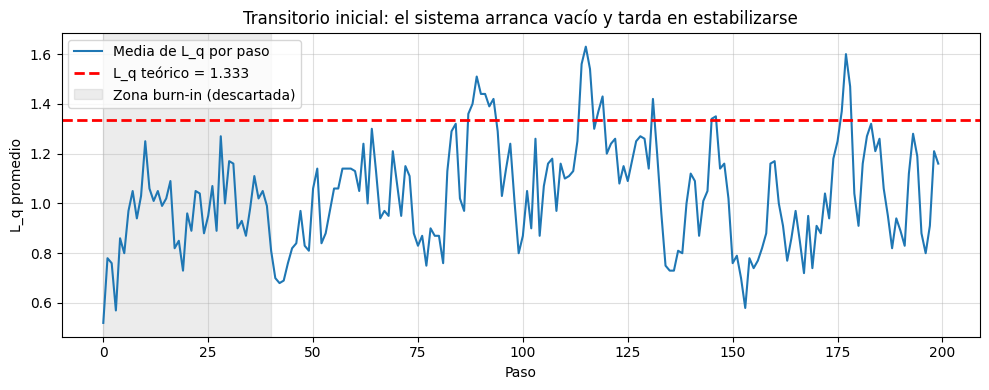

L_q promedio en los primeros 40 pasos (transitorio): 0.958  ← sesgado hacia abajo
L_q promedio después del burn-in:                              1.055  ← converge al valor teórico
L_q teórico (fórmula exacta):                                  1.333


In [14]:
# ── ¿Por qué necesitamos burn-in? Visualizando el transitorio ────────────────
lam     = 4
mu      = 6     # M/M/1 con rho = 4/6 ≈ 0.67
n_pasos = 200
n_rep   = 100

# Corremos varias réplicas y guardamos los historiales
all_colas = np.zeros((n_rep, n_pasos))
cola      = 0
for i in range(n_rep):
    cola = 0                                # cada réplica arranca vacía
    for t in range(n_pasos):
        cola += np.random.poisson(lam)
        cola -= min(cola, np.random.poisson(mu))
        all_colas[i, t] = cola

media_por_paso = all_colas.mean(axis=0)    # promedio entre réplicas en cada paso
valor_teorico  = analitico_mm1(lam, mu)["Lq"]  # L_q exacto de las fórmulas

plt.figure(figsize=(10, 4))
plt.plot(media_por_paso, color='C0', linewidth=1.5, label="Media de L_q por paso")
plt.axhline(valor_teorico, color='red', linestyle='--', linewidth=2,
            label=f"L_q teórico = {valor_teorico:.3f}")
plt.axvspan(0, n_pasos // 5, color='gray', alpha=0.15,
            label="Zona burn-in (descartada)")
plt.xlabel("Paso")
plt.ylabel("L_q promedio")
plt.title("Transitorio inicial: el sistema arranca vacío y tarda en estabilizarse")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

print(f"L_q promedio en los primeros {n_pasos//5} pasos (transitorio): "
      f"{media_por_paso[:n_pasos//5].mean():.3f}  ← sesgado hacia abajo")
print(f"L_q promedio después del burn-in:                              "
      f"{media_por_paso[n_pasos//5:].mean():.3f}  ← converge al valor teórico")
print(f"L_q teórico (fórmula exacta):                                  "
      f"{valor_teorico:.3f}")


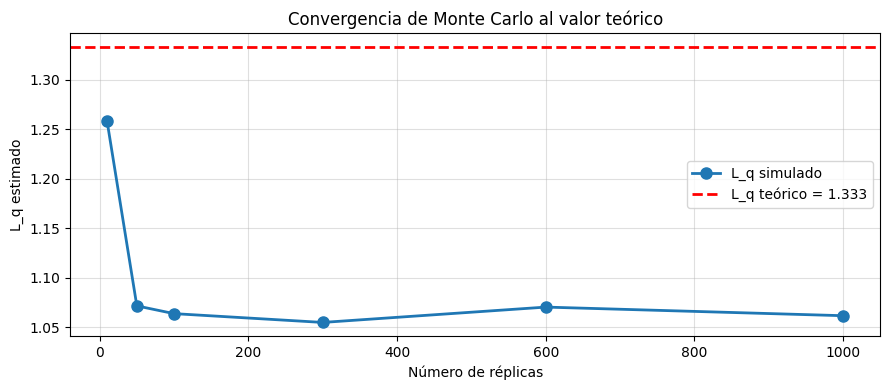


Comparación simulación vs. fórmulas exactas (M/M/1, 600 réplicas):
Métrica      Simulación       Exacto    Error %
------------------------------------------------
L                2.0411       2.0000      2.06%
Lq               1.0551       1.3333     20.86%
Ls               0.9860       0.6667     47.89%
W                0.5103       0.5000      2.06%
Wq               0.2638       0.3333     20.86%
Ws               0.2465       0.1667     47.89%


In [15]:
# ── Convergencia: ¿cuántas réplicas necesitamos? ─────────────────────────────
lam     = 4
mu      = 6
n_pasos = 300
teorico = analitico_mm1(lam, mu)

n_reps_a_probar = [10, 50, 100, 300, 600, 1000]
Lq_sim_vals     = []

for n_rep in n_reps_a_probar:
    r = simular_mms(lam, mu, s=1, n_pasos=n_pasos, n_rep=n_rep)
    Lq_sim_vals.append(r["Lq"])

plt.figure(figsize=(9, 4))
plt.plot(n_reps_a_probar, Lq_sim_vals, '-o', linewidth=2, markersize=8, label="L_q simulado")
plt.axhline(teorico["Lq"], color='red', linestyle='--', linewidth=2,
            label=f"L_q teórico = {teorico['Lq']:.3f}")
plt.xlabel("Número de réplicas")
plt.ylabel("L_q estimado")
plt.title("Convergencia de Monte Carlo al valor teórico")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

# Tabla de comparación completa
print("\nComparación simulación vs. fórmulas exactas (M/M/1, 600 réplicas):")
sim = simular_mms(lam, mu, s=1, n_pasos=n_pasos, n_rep=600)
print(f"{'Métrica':10} {'Simulación':>12} {'Exacto':>12} {'Error %':>10}")
print("-" * 48)
for key in ["L", "Lq", "Ls", "W", "Wq", "Ws"]:
    s_val = sim[key]
    t_val = teorico[key]
    err   = abs(s_val - t_val) / t_val * 100
    print(f"{key:10} {s_val:>12.4f} {t_val:>12.4f} {err:>9.2f}%")


---
# Problema 1 — Banco: ¿Cuántos cajeros contratar?

Un banco recibe en promedio **λ = 4 clientes/hora** y cada cajero atiende **μ = 2 clientes/hora**.

**Función de costos:**
$$C(s) = 10 \cdot L_q(s) + 15 \cdot s$$

- **\$10/cliente-hora en cola** → insatisfacción, riesgo de que el cliente se vaya  
- **\$15/cajero-hora** → salario  

**Notación Kendall:** M/M/s — llegadas Poisson, servicio exponencial, s cajeros, sin límite de capacidad.


Media de clientes en cola (Lq):  23.74
Costo total = 10·23.74 + 15·2 = 267.40 $/hora


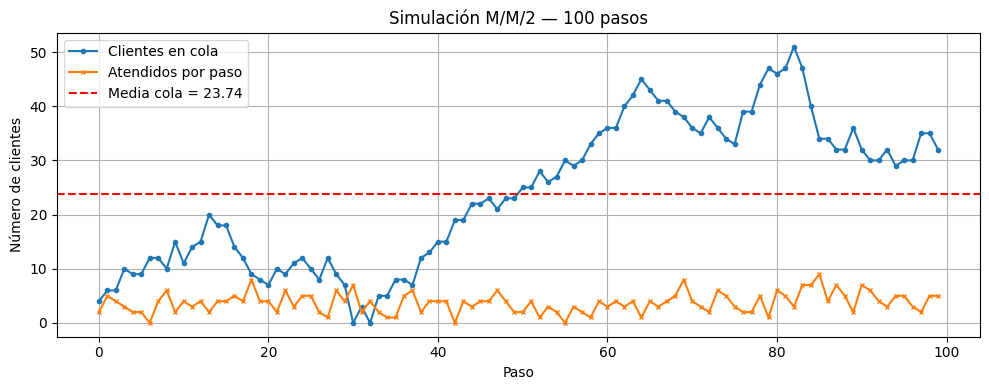

In [16]:
# ── Simulación simple: un solo s para ver la dinámica ────────────────────────
lam            = 4
mu             = 2
s              = 2
n_pasos        = 100
costo_espera   = 10
costo_servidor = 15

hist_cola      = []
hist_atendidos = []
cola           = 0

for paso in range(n_pasos):
    llegadas  = np.random.poisson(lam)      # clientes que llegan este paso
    cola     += llegadas
    capacidad = np.random.poisson(s * mu)   # capacidad máxima de atención
    atendidos = min(cola, capacidad)        # no se puede atender más de los que hay
    cola     -= atendidos
    hist_cola.append(cola)
    hist_atendidos.append(atendidos)

media_cola  = np.mean(hist_cola)
costo_total = costo_espera * media_cola + costo_servidor * s

print(f"Media de clientes en cola (Lq):  {media_cola:.2f}")
print(f"Costo total = {costo_espera}·{media_cola:.2f} + {costo_servidor}·{s} = {costo_total:.2f} $/hora")

plt.figure(figsize=(10, 4))
plt.plot(hist_cola,      label="Clientes en cola",   marker='o', markersize=3)
plt.plot(hist_atendidos, label="Atendidos por paso", marker='x', markersize=3)
plt.axhline(media_cola, color='r', linestyle='--', label=f"Media cola = {media_cola:.2f}")
plt.xlabel("Paso")
plt.ylabel("Número de clientes")
plt.title(f"Simulación M/M/{s} — {n_pasos} pasos")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


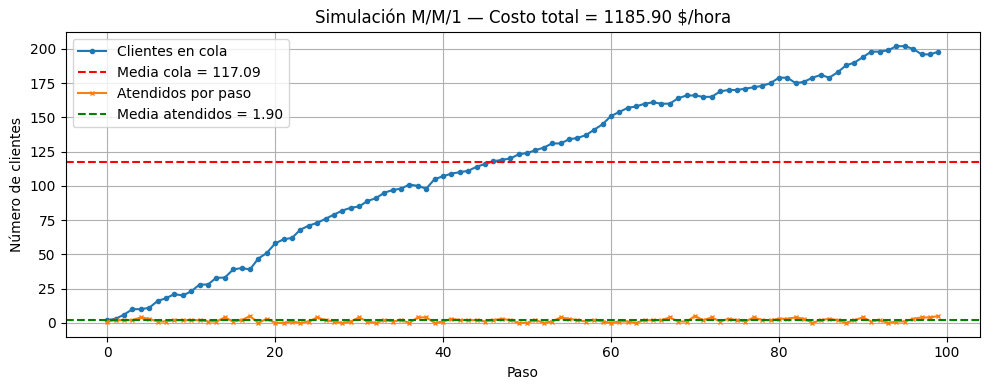

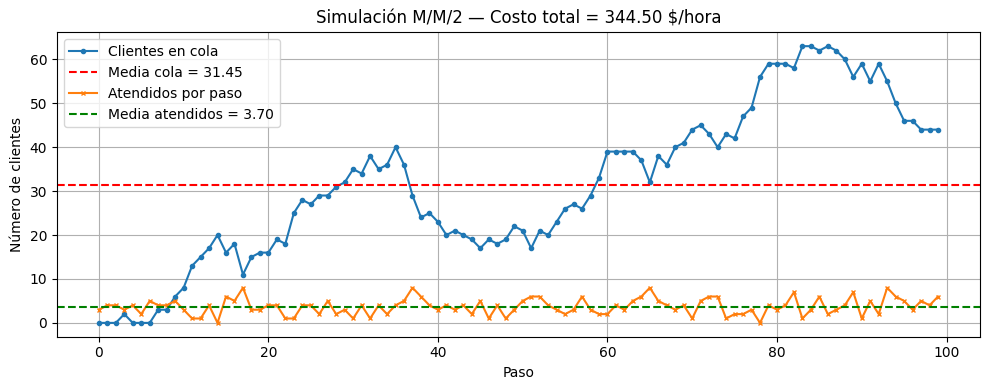

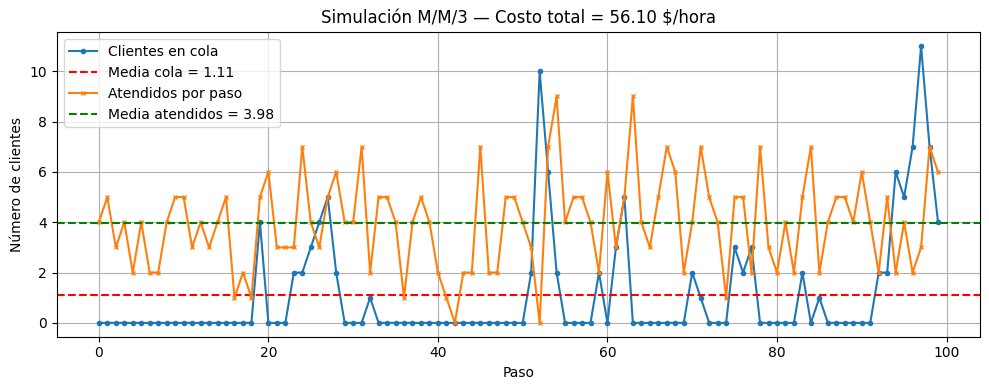

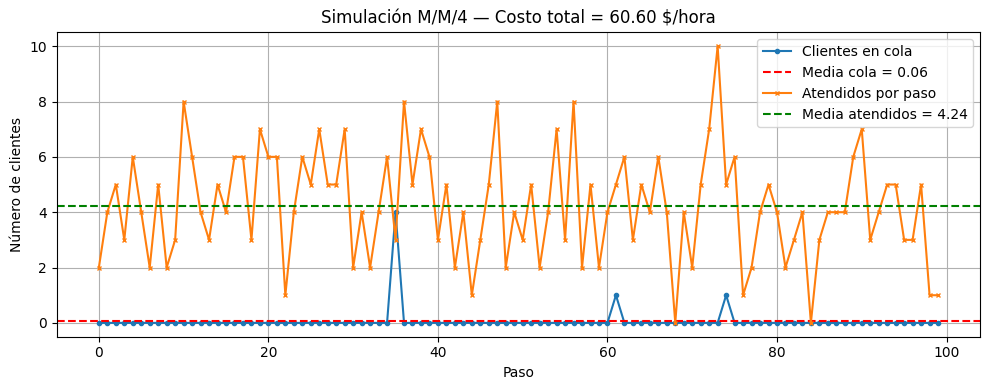

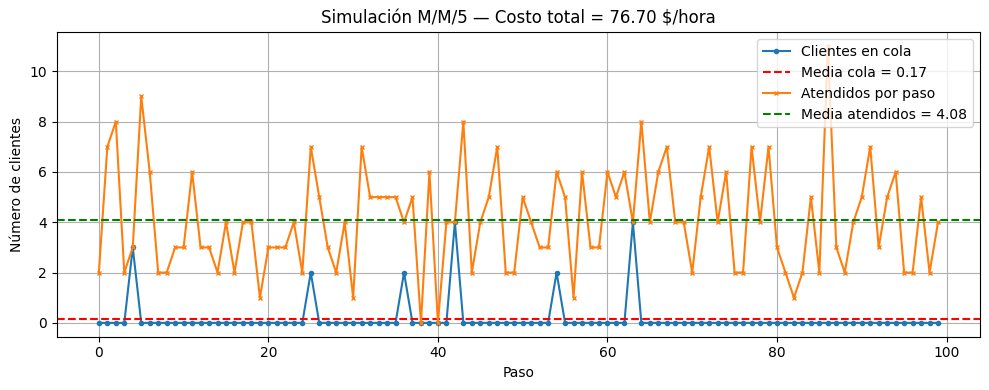

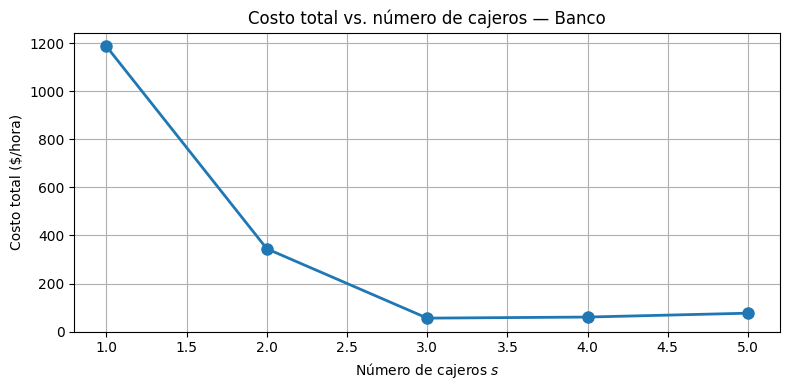


→ Cajero óptimo: s* = 3  |  Costo mínimo = 56.10 $/hora


In [17]:
# ── Distintos valores de s: costo vs. número de cajeros ──────────────────────
lam            = 4
mu             = 2
s_max          = 5
n_pasos        = 100
costo_espera   = 10
costo_servidor = 15

costos_totales = []

for s in range(1, s_max + 1):
    hist_cola = []
    hist_att  = []
    cola      = 0
    for _ in range(n_pasos):
        cola     += np.random.poisson(lam)
        atend     = min(cola, np.random.poisson(s * mu))
        cola     -= atend
        hist_cola.append(cola)
        hist_att.append(atend)

    media_cola  = np.mean(hist_cola)
    costo_total = costo_espera * media_cola + costo_servidor * s
    costos_totales.append(costo_total)

    plt.figure(figsize=(10, 4))
    plt.plot(hist_cola, label="Clientes en cola",   marker='o', markersize=3)
    plt.axhline(media_cola, color='r', linestyle='--',
                label=f"Media cola = {media_cola:.2f}")
    plt.plot(hist_att,  label="Atendidos por paso", marker='x', markersize=3)
    plt.axhline(np.mean(hist_att), color='g', linestyle='--',
                label=f"Media atendidos = {np.mean(hist_att):.2f}")
    plt.xlabel("Paso")
    plt.ylabel("Número de clientes")
    plt.title(f"Simulación M/M/{s} — Costo total = {costo_total:.2f} $/hora")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8, 4))
plt.plot(range(1, s_max + 1), costos_totales, '-o', linewidth=2, markersize=8)
plt.xlabel("Número de cajeros $s$")
plt.ylabel("Costo total ($/hora)")
plt.title("Costo total vs. número de cajeros — Banco")
plt.grid(True)
plt.tight_layout()
plt.show()

s_opt = np.argmin(costos_totales) + 1
print(f"\n→ Cajero óptimo: s* = {s_opt}  |  Costo mínimo = {costos_totales[s_opt-1]:.2f} $/hora")


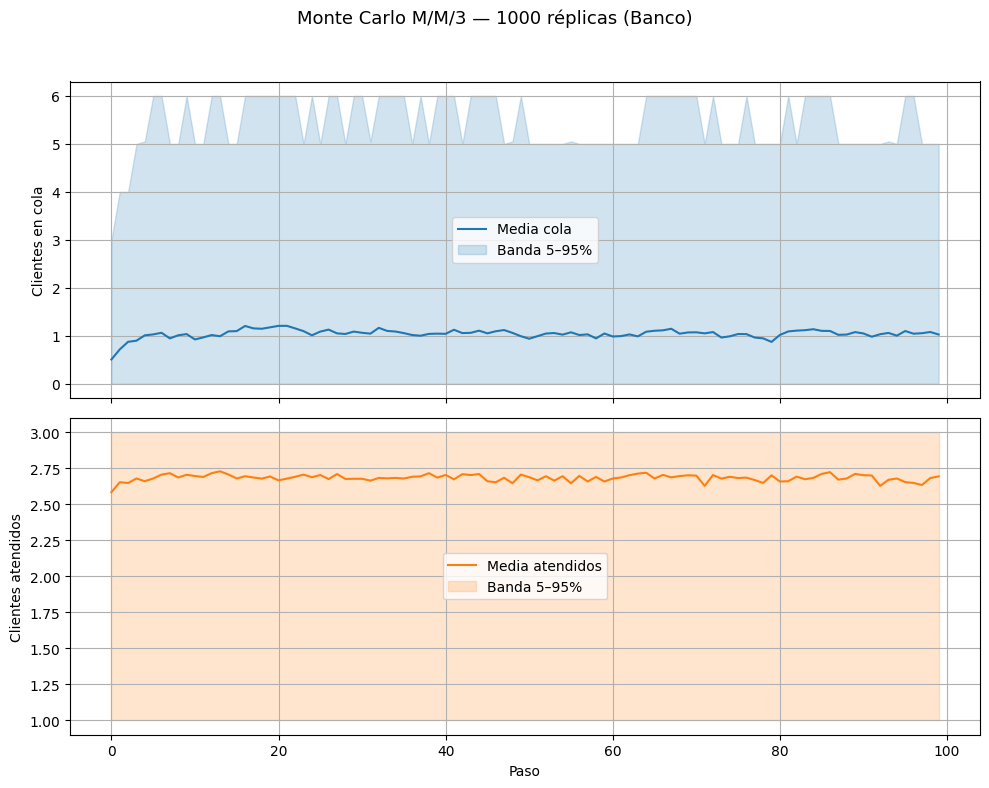

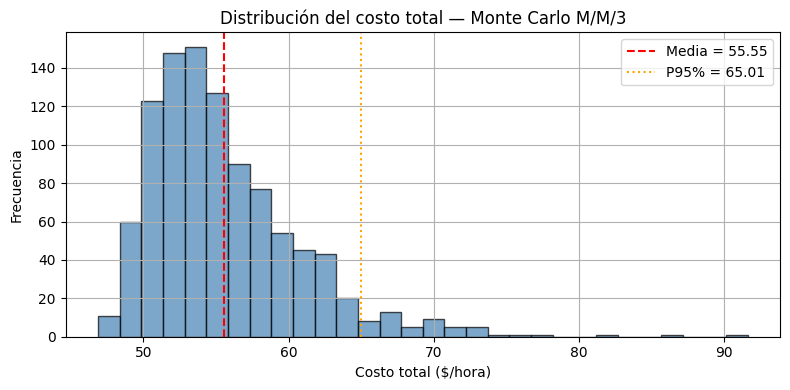

Costo medio:       55.55 $/hora
Desvío estándar:   5.22 $/hora
Percentil  5%:     49.50 $/hora
Percentil 95%:     65.01 $/hora


In [18]:
# ── Monte Carlo: distribución del costo (s fijo) ─────────────────────────────
lam            = 4
mu             = 2
s              = 3
n_pasos        = 100
n_rep          = 1000
costo_espera   = 10
costo_servidor = 15

r = simular_mms(lam, mu, s, n_pasos, n_rep,
                costo_espera=costo_espera, costo_servidor=costo_servidor)

all_colas  = r["all_colas"]
all_att    = r["all_att"]
all_costos = r["todas_costo"]

mean_cola = all_colas.mean(axis=0)
p5_cola, p95_cola = np.percentile(all_colas, [5, 95], axis=0)
mean_att  = all_att.mean(axis=0)
p5_att,  p95_att  = np.percentile(all_att,   [5, 95], axis=0)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].plot(mean_cola, color='C0', label='Media cola')
axes[0].fill_between(range(n_pasos), p5_cola, p95_cola,
                     color='C0', alpha=0.2, label='Banda 5–95%')
axes[0].set_ylabel('Clientes en cola')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(mean_att, color='C1', label='Media atendidos')
axes[1].fill_between(range(n_pasos), p5_att, p95_att,
                     color='C1', alpha=0.2, label='Banda 5–95%')
axes[1].set_xlabel('Paso')
axes[1].set_ylabel('Clientes atendidos')
axes[1].legend()
axes[1].grid(True)

plt.suptitle(f'Monte Carlo M/M/{s} — {n_rep} réplicas (Banco)', fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(all_costos, bins=30, edgecolor='k', alpha=0.7, color='steelblue')
plt.axvline(all_costos.mean(), color='r', linestyle='--',
            label=f'Media = {all_costos.mean():.2f}')
plt.axvline(np.percentile(all_costos, 95), color='orange', linestyle=':',
            label=f'P95% = {np.percentile(all_costos, 95):.2f}')
plt.xlabel('Costo total ($/hora)')
plt.ylabel('Frecuencia')
plt.title(f'Distribución del costo total — Monte Carlo M/M/{s}')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Costo medio:       {all_costos.mean():.2f} $/hora")
print(f"Desvío estándar:   {all_costos.std():.2f} $/hora")
print(f"Percentil  5%:     {np.percentile(all_costos,  5):.2f} $/hora")
print(f"Percentil 95%:     {np.percentile(all_costos, 95):.2f} $/hora")


⚠️  SISTEMA INESTABLE: ρ = 2.00 ≥ 1  (λ=4, s=1, μ=2)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.00 ≥ 1  (λ=4, s=2, μ=2)
    Las métricas no tienen sentido en estado estacionario.


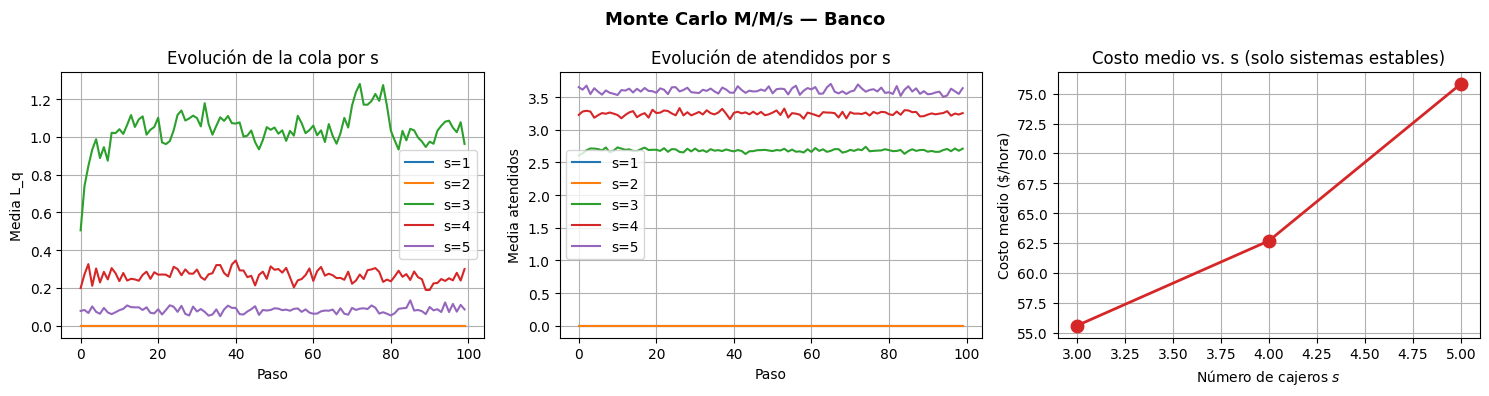


→ s óptimo (Monte Carlo): s* = 3
  Costo medio mínimo = 55.58 $/hora
  Desglose: costo espera ≈ 10.54  |  costo personal = 45.00


In [19]:
# ── Monte Carlo para todos los s: costo medio y óptimo ───────────────────────
lam            = 4
mu             = 2
s_max          = 5
n_pasos        = 100
n_rep          = 1000
costo_espera   = 10
costo_servidor = 15

cola_means   = np.zeros((s_max, n_pasos))
att_means    = np.zeros((s_max, n_pasos))
costos_means = np.full(s_max, np.inf)      # ← np.inf en vez de 0: los inestables nunca ganan

for s in range(1, s_max + 1):
    r = simular_mms(lam, mu, s, n_pasos, n_rep,
                    costo_espera=costo_espera, costo_servidor=costo_servidor)
    if r is None:
        continue                           # sistema inestable, salteamos
    cola_means[s-1]   = r["all_colas"].mean(axis=0)
    att_means[s-1]    = r["all_att"].mean(axis=0)
    costos_means[s-1] = r["costo_total"]

# Para graficar solo los estables
s_estables    = [s for s in range(1, s_max + 1) if not np.isinf(costos_means[s-1])]
costos_graf   = [costos_means[s-1] for s in s_estables]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Monte Carlo M/M/s — Banco", fontsize=13, fontweight='bold')

for idx in range(s_max):
    axes[0].plot(cola_means[idx], label=f's={idx+1}')
axes[0].set_xlabel('Paso'); axes[0].set_ylabel('Media L_q')
axes[0].set_title('Evolución de la cola por s')
axes[0].legend(); axes[0].grid(True)

for idx in range(s_max):
    axes[1].plot(att_means[idx], label=f's={idx+1}')
axes[1].set_xlabel('Paso'); axes[1].set_ylabel('Media atendidos')
axes[1].set_title('Evolución de atendidos por s')
axes[1].legend(); axes[1].grid(True)

axes[2].plot(s_estables, costos_graf, '-o', linewidth=2, markersize=9, color='C3')
axes[2].set_xlabel('Número de cajeros $s$'); axes[2].set_ylabel('Costo medio ($/hora)')
axes[2].set_title('Costo medio vs. s (solo sistemas estables)')
axes[2].grid(True)

plt.tight_layout()
plt.show()

s_opt = s_estables[np.argmin(costos_graf)]          # ← busca el mínimo solo entre estables
print(f"\n→ s óptimo (Monte Carlo): s* = {s_opt}")
print(f"  Costo medio mínimo = {costos_means[s_opt-1]:.2f} $/hora")
r_opt = simular_mms(lam, mu, s_opt, n_pasos, n_rep,
                    costo_espera=costo_espera, costo_servidor=costo_servidor)
print(f"  Desglose: costo espera ≈ {costo_espera * r_opt['Lq']:.2f}  |  "
      f"costo personal = {costo_servidor * s_opt:.2f}")

---
# Problema 2 — Soporte Técnico: ¿Cuántos técnicos contratar?

Una empresa recibe **λ = 6 computadoras/hora**. Cada técnico tarda 20 min → **μ = 3/hora**.

$$C(s) = 12 \cdot L_q(s) + 20 \cdot s$$

- **\$12/hora por computadora en espera** → costo operativo de equipos parados  
- **\$20/hora por técnico** → salario


In [20]:
# ── Optimización con fórmulas analíticas + simulación ────────────────────────
lam            = 6
mu             = 3
s_max          = 5
n_pasos        = 200
n_rep          = 600
costo_espera   = 12
costo_tecnico  = 20

print(f"Verificación analítica vs. simulación (M/M/s, λ={lam}, μ={mu})")
print(f"{'s':>4} {'ρ':>6} {'L_q analitico':>15} {'L_q simulado':>14} {'C_total':>10}")
print("-" * 58)

resultados = []
for s in range(1, s_max + 1):
    rho = lam / (s * mu)
    if rho >= 1:
        print(f"{s:>4} {rho:>6.2f}  {'—':>15} {'—':>14} {'—':>10}  ✗ inestable")
        continue
    teo = analitico_mms(lam, mu, s)
    r   = simular_mms(lam, mu, s, n_pasos, n_rep,
                      costo_espera=costo_espera, costo_servidor=costo_tecnico)
    r["s"] = s
    resultados.append(r)
    print(f"{s:>4} {rho:>6.2f} {teo['Lq']:>15.3f} {r['Lq']:>14.3f} {r['costo_total']:>10.2f}  ✔")

s_opt = min(resultados, key=lambda r: r["costo_total"])["s"]
print(f"\n→ Técnicos óptimos: s* = {s_opt}")


Verificación analítica vs. simulación (M/M/s, λ=6, μ=3)
   s      ρ   L_q analitico   L_q simulado    C_total
----------------------------------------------------------
   1   2.00                —              —          —  ✗ inestable
   2   1.00                —              —          —  ✗ inestable
   3   0.67           0.889          0.884      70.61  ✔
   4   0.50           0.174          0.172      82.06  ✔
   5   0.40           0.040          0.038     100.46  ✔

→ Técnicos óptimos: s* = 3


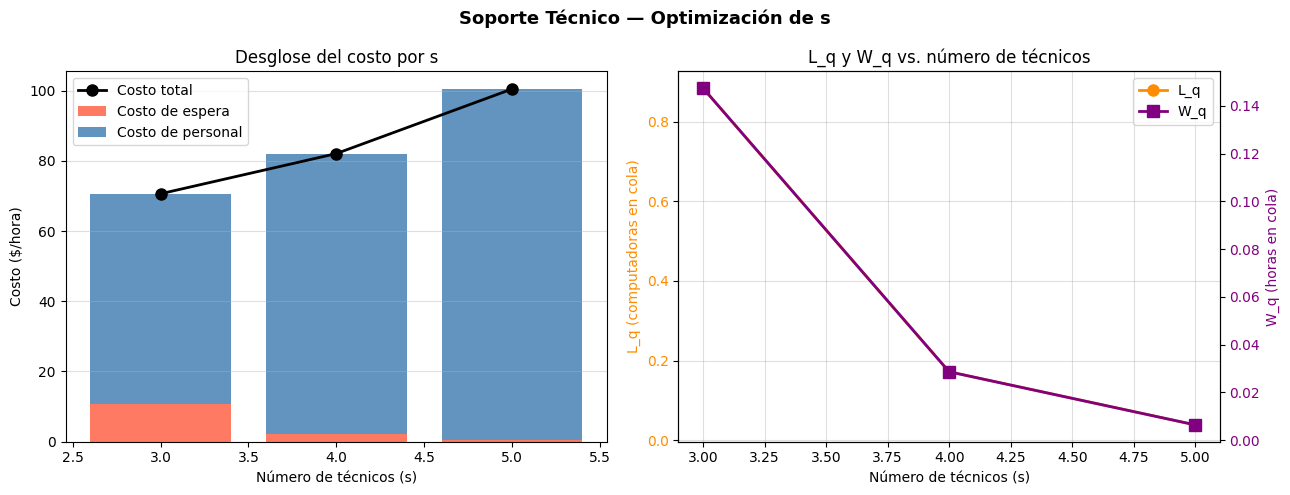

In [21]:
# ── Desglose del costo: espera vs. personal ───────────────────────────────────
estables   = resultados
s_v        = [r["s"]                          for r in estables]
c_espera_v = [costo_espera   * r["Lq"]        for r in estables]
c_tecnico_v= [costo_tecnico  * r["s"]         for r in estables]
c_total_v  = [r["costo_total"]                for r in estables]
Lq_v       = [r["Lq"]                         for r in estables]
Wq_v       = [r["Wq"]                         for r in estables]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Soporte Técnico — Optimización de s", fontsize=13, fontweight='bold')

axes[0].bar(s_v, c_espera_v,  label="Costo de espera",   color='tomato',     alpha=0.85)
axes[0].bar(s_v, c_tecnico_v, label="Costo de personal", color='steelblue',
            alpha=0.85, bottom=c_espera_v)
axes[0].plot(s_v, c_total_v, '-o', color='black', linewidth=2, markersize=8, label="Costo total")
axes[0].set_xlabel("Número de técnicos (s)")
axes[0].set_ylabel("Costo ($/hora)")
axes[0].set_title("Desglose del costo por s")
axes[0].legend(); axes[0].grid(True, alpha=0.4, axis='y')

ax2 = axes[1]
ax3 = ax2.twinx()
ax2.plot(s_v, Lq_v, '-o', color='darkorange', linewidth=2, markersize=8, label="L_q")
ax3.plot(s_v, Wq_v, '-s', color='purple',     linewidth=2, markersize=8, label="W_q")
ax2.set_xlabel("Número de técnicos (s)")
ax2.set_ylabel("L_q (computadoras en cola)", color='darkorange')
ax2.tick_params(axis='y', labelcolor='darkorange')
ax3.set_ylabel("W_q (horas en cola)", color='purple')
ax3.tick_params(axis='y', labelcolor='purple')
ax2.set_title("L_q y W_q vs. número de técnicos")
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax3.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


In [22]:
# ── Extensión: M/M/3/K — capacidad máxima ─────────────────────────────────────
lam           = 6
mu            = 3
s             = 3
K             = 8
n_pasos       = 200
n_rep         = 600
costo_espera  = 12
costo_tecnico = 20
costo_rechazo = 50   # costo por computadora rechazada

r_sin = simular_mms( lam, mu, s, n_pasos, n_rep,
                     costo_espera=costo_espera, costo_servidor=costo_tecnico)
r_con = simular_mmsk(lam, mu, s, K, n_pasos, n_rep,
                     costo_espera=costo_espera, costo_servidor=costo_tecnico,
                     costo_perdida=costo_rechazo)

print("Comparación M/M/3 vs. M/M/3/8")
print("=" * 52)
print(f"{'Métrica':22} {'M/M/3':>12} {'M/M/3/8':>12}")
print("-" * 52)
for key, label in [("L","L"),("Lq","L_q"),("Ls","L_s"),
                   ("W","W (h)"),("Wq","W_q (h)"),("Ws","W_s (h)")]:
    print(f"{label:22} {r_sin[key]:>12.3f} {r_con[key]:>12.3f}")
print(f"{'% rechazados':22} {'—':>12} {r_con['tasa_perdida']*100:>11.1f}%")
print(f"{'Costo total ($/h)':22} {r_sin['costo_total']:>12.2f} {r_con['costo_total']:>12.2f}")
print()
print("📌 El sistema con K limita la espera pero paga un costo de rechazo.")


Comparación M/M/3 vs. M/M/3/8
Métrica                       M/M/3      M/M/3/8
----------------------------------------------------
L                             3.820        3.249
L_q                           0.887        0.326
L_s                           2.933        2.923
W (h)                         0.637        0.542
W_q (h)                       0.148        0.054
W_s (h)                       0.489        0.487
% rechazados                      —         7.3%
Costo total ($/h)             70.64        85.80

📌 El sistema con K limita la espera pero paga un costo de rechazo.


---
# Problema 3 — Call Center de E-commerce

**λ = 10 llamadas/hora**, **μ = 4 llamadas/agente/hora**.

$$C(s) = 8 \cdot L_q(s) + 18 \cdot s$$

Se busca el número óptimo de agentes y se analiza la **sensibilidad** ante cambios en λ y μ.


   s      ρ        L      L_q   W_q(h)    C_total
----------------------------------------------------
⚠️  SISTEMA INESTABLE: ρ = 2.50 ≥ 1  (λ=10, s=1, μ=4)
    Las métricas no tienen sentido en estado estacionario.
   1  —  sistema inestable
⚠️  SISTEMA INESTABLE: ρ = 1.25 ≥ 1  (λ=10, s=2, μ=4)
    Las métricas no tienen sentido en estado estacionario.
   2  —  sistema inestable
   3   0.83    6.255    3.257    0.326      80.06
   4   0.62    4.371    0.383    0.038      75.07
   5   0.50    5.032    0.074    0.007      90.59
   6   0.42    5.903    0.013    0.001     108.10

→ Agentes óptimos: s* = 4


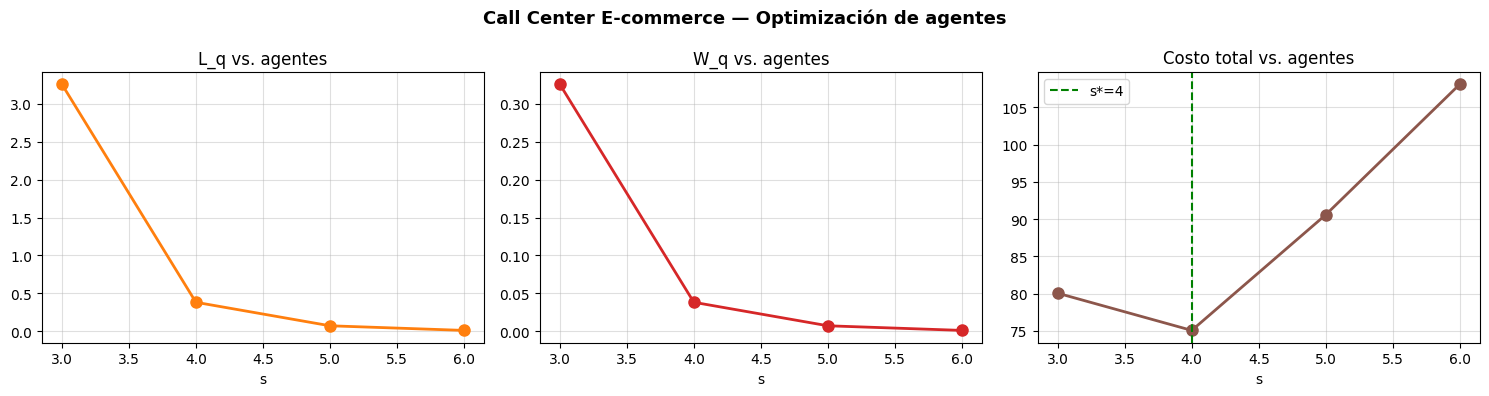

In [23]:
# ── Optimización de agentes ───────────────────────────────────────────────────
lam           = 10
mu            = 4
s_max         = 6
n_pasos       = 200
n_rep         = 600
costo_espera  = 8
costo_agente  = 18

resultados_cc = []
print(f"{'s':>4} {'ρ':>6} {'L':>8} {'L_q':>8} {'W_q(h)':>8} {'C_total':>10}")
print("-" * 52)
for s in range(1, s_max + 1):
    r = simular_mms(lam, mu, s, n_pasos, n_rep,
                    costo_espera=costo_espera, costo_servidor=costo_agente)
    if r is None:
        print(f"{s:>4}  —  sistema inestable")
        continue
    r["s"] = s
    resultados_cc.append(r)
    print(f"{s:>4} {r['rho']:>6.2f} {r['L']:>8.3f} {r['Lq']:>8.3f} "
          f"{r['Wq']:>8.3f} {r['costo_total']:>10.2f}")

estables_cc = resultados_cc
s_opt_cc    = min(estables_cc, key=lambda r: r["costo_total"])["s"]
print(f"\n→ Agentes óptimos: s* = {s_opt_cc}")

s_e  = [r["s"]           for r in estables_cc]
ct_e = [r["costo_total"] for r in estables_cc]
Lq_e = [r["Lq"]          for r in estables_cc]
Wq_e = [r["Wq"]          for r in estables_cc]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Call Center E-commerce — Optimización de agentes",
             fontsize=13, fontweight='bold')

axes[0].plot(s_e, Lq_e, '-o', color='C1', linewidth=2, markersize=8)
axes[0].set_title("L_q vs. agentes"); axes[0].set_xlabel("s")
axes[0].grid(True, alpha=0.4)

axes[1].plot(s_e, Wq_e, '-o', color='C3', linewidth=2, markersize=8)
axes[1].set_title("W_q vs. agentes"); axes[1].set_xlabel("s")
axes[1].grid(True, alpha=0.4)

axes[2].plot(s_e, ct_e, '-o', color='C5', linewidth=2, markersize=8)
axes[2].axvline(s_opt_cc, color='green', linestyle='--', label=f"s*={s_opt_cc}")
axes[2].set_title("Costo total vs. agentes"); axes[2].set_xlabel("s")
axes[2].legend(); axes[2].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


⚠️  SISTEMA INESTABLE: ρ = 1.04 ≥ 1  (λ=10, s=4, μ=2.4)
    Las métricas no tienen sentido en estado estacionario.


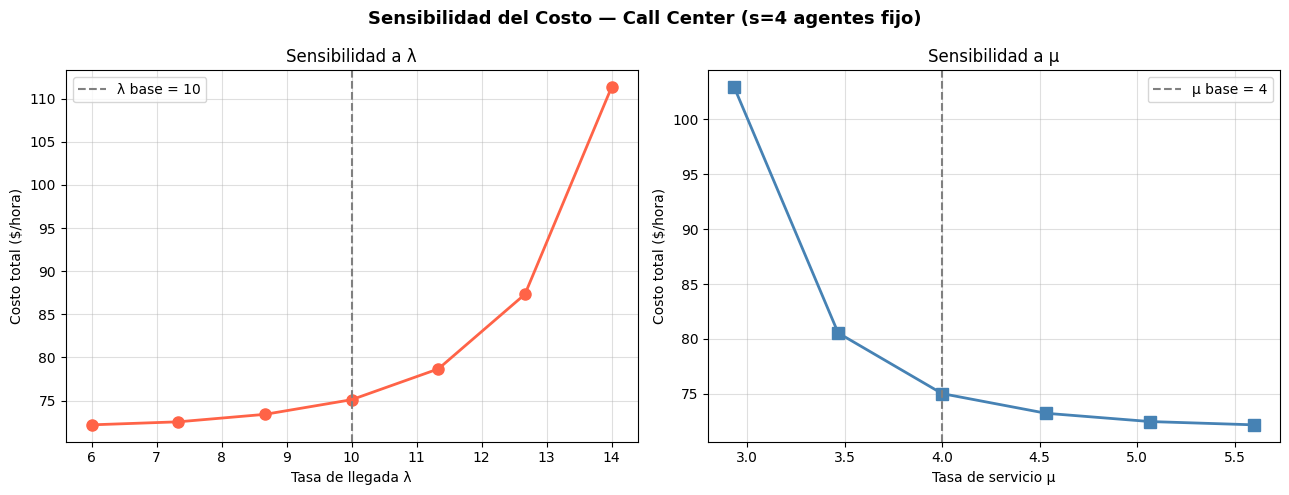


📌 Si λ crece un 40% el costo se dispara (ρ se acerca a 1).
   Un μ mayor (mejor capacitación) reduce el costo de forma más suave.
   Invertir en velocidad de servicio es más estabilizador que agregar agentes.


In [24]:
# ── Análisis de sensibilidad: ¿qué tan estable es el sistema? ─────────────────
# Fijamos s = s_opt y variamos λ y μ ±40% alrededor de sus valores base
s        = s_opt_cc
lam_base = 10
mu_base  = 4
n_pasos  = 200
n_rep    = 500

lambdas = np.linspace(lam_base * 0.6, lam_base * 1.4, 7)
mus     = np.linspace(mu_base  * 0.6, mu_base  * 1.4, 7)

costo_lam = []
costo_mu  = []

for lam_v in lambdas:
    r = simular_mms(lam_v, mu_base, s, n_pasos, n_rep,
                    costo_espera=costo_espera, costo_servidor=costo_agente)
    costo_lam.append(r["costo_total"] if r else np.nan)

for mu_v in mus:
    r = simular_mms(lam_base, mu_v, s, n_pasos, n_rep,
                    costo_espera=costo_espera, costo_servidor=costo_agente)
    costo_mu.append(r["costo_total"] if r else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"Sensibilidad del Costo — Call Center (s={s} agentes fijo)",
             fontsize=13, fontweight='bold')

axes[0].plot(lambdas, costo_lam, '-o', color='tomato', linewidth=2, markersize=8)
axes[0].axvline(lam_base, color='gray', linestyle='--', label=f'λ base = {lam_base}')
axes[0].set_xlabel("Tasa de llegada λ"); axes[0].set_ylabel("Costo total ($/hora)")
axes[0].set_title("Sensibilidad a λ"); axes[0].legend(); axes[0].grid(True, alpha=0.4)

axes[1].plot(mus, costo_mu, '-s', color='steelblue', linewidth=2, markersize=8)
axes[1].axvline(mu_base, color='gray', linestyle='--', label=f'μ base = {mu_base}')
axes[1].set_xlabel("Tasa de servicio μ"); axes[1].set_ylabel("Costo total ($/hora)")
axes[1].set_title("Sensibilidad a μ"); axes[1].legend(); axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print("\n📌 Si λ crece un 40% el costo se dispara (ρ se acerca a 1).")
print("   Un μ mayor (mejor capacitación) reduce el costo de forma más suave.")
print("   Invertir en velocidad de servicio es más estabilizador que agregar agentes.")


---
# Problema 4 — Supermercado Online: Capacidad máxima y pedidos perdidos

**λ = 8 pedidos/min**, **μ = 3/servidor/min**, **s = 3 servidores**.  
El sistema acepta hasta **K pedidos** en total (cola + servicio).

$$C(s,K) = c_{\text{espera}} \cdot L_q + c_{\text{servidor}} \cdot s + c_{\text{rechazo}} \cdot \lambda_{\text{perdida}}$$

- **\$5/pedido-min en cola** · **\$25/servidor/min** · **\$40/pedido rechazado/min**


In [25]:
# ── Efecto de K sobre métricas y costo total ─────────────────────────────────
lam            = 8
mu             = 3
s              = 3
K_lista        = [4, 6, 8, 12, 20, 50]
n_pasos        = 200
n_rep          = 500
costo_espera   = 5
costo_servidor = 25
costo_rechazo  = 40

res_K = []
for K in K_lista:
    r = simular_mmsk(lam, mu, s, K, n_pasos, n_rep,
                     costo_espera=costo_espera,
                     costo_servidor=costo_servidor,
                     costo_perdida=costo_rechazo)
    r["K"] = K
    res_K.append(r)

print(f"{'K':>5} {'L_q':>7} {'W_q':>7} {'%Rechazo':>10} {'C_total':>10}")
print("-" * 45)
for r in res_K:
    print(f"{r['K']:>5} {r['Lq']:>7.3f} {r['Wq']:>7.3f} "
          f"{r['tasa_perdida']*100:>9.1f}% {r['costo_total']:>10.2f}")


    K     L_q     W_q   %Rechazo    C_total
---------------------------------------------
    4   0.028   0.003      51.1%     238.78
    6   0.166   0.021      31.0%     175.19
    8   0.527   0.066      18.3%     136.31
   12   1.591   0.199       7.3%     106.42
   20   3.645   0.456       2.1%     100.04
   50   6.086   0.761       0.0%     105.59


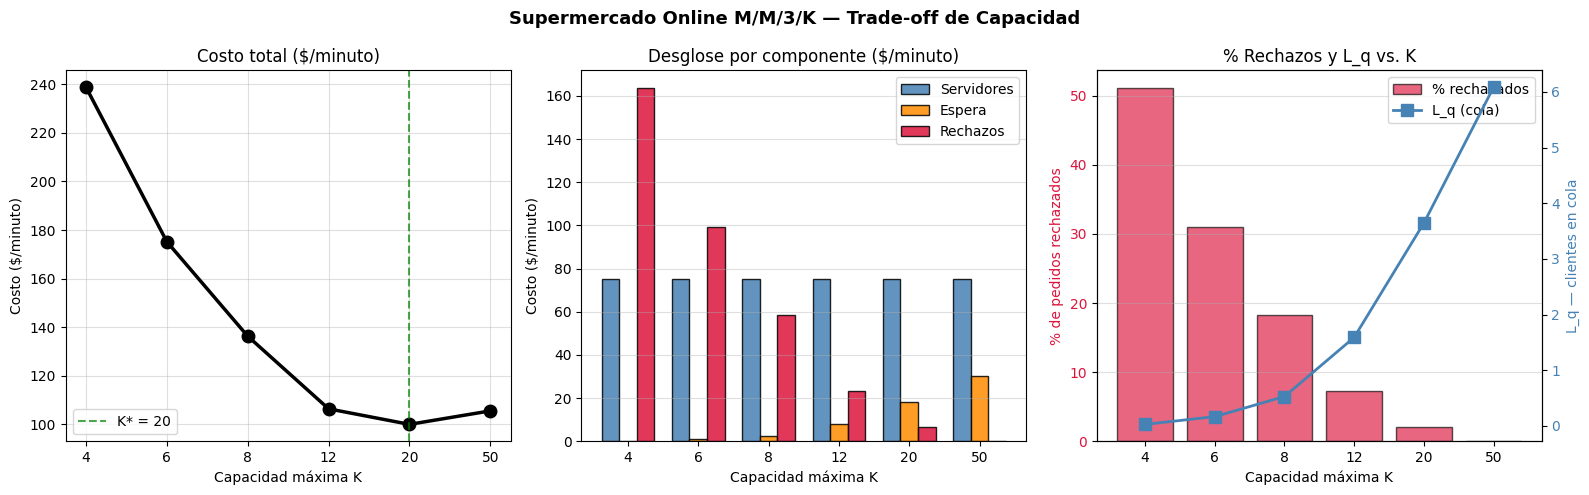


→ K óptimo: K* = 20  |  Costo mínimo = 100.04 $/minuto
  Desglose: servidores=75.0  |  espera=18.2  |  rechazos=6.8


In [26]:
# ── Tres paneles: costo total, desglose, rechazos vs. L_q ────────────────────
K_labels = [str(k) for k in K_lista]
c_esp    = np.array([costo_espera   * r["Lq"]                 for r in res_K])
c_serv   = np.array([costo_servidor * s                       for r in res_K])
c_rec    = np.array([costo_rechazo  * r["tasa_perdida"] * lam for r in res_K])
c_tot    = np.array([r["costo_total"]                         for r in res_K])
perd_v   = np.array([r["tasa_perdida"] * 100                  for r in res_K])
Lq_v     = np.array([r["Lq"]                                  for r in res_K])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Supermercado Online M/M/3/K — Trade-off de Capacidad",
             fontsize=13, fontweight='bold')

# Panel 1: Costo total
idx_opt = np.argmin(c_tot)
axes[0].plot(K_labels, c_tot, '-o', color='black', linewidth=2.5, markersize=9)
axes[0].axvline(K_labels[idx_opt], color='green', linestyle='--', alpha=0.7,
                label=f"K* = {K_lista[idx_opt]}")
axes[0].set_title("Costo total ($/minuto)")
axes[0].set_xlabel("Capacidad máxima K"); axes[0].set_ylabel("Costo ($/minuto)")
axes[0].legend(); axes[0].grid(True, alpha=0.4)

# Panel 2: Desglose de componentes (barras agrupadas, misma escala)
x = np.arange(len(K_labels))
w = 0.25
axes[1].bar(x - w, c_serv, width=w, label="Servidores",  color='steelblue',  alpha=0.85, edgecolor='k')
axes[1].bar(x,     c_esp,  width=w, label="Espera",      color='darkorange', alpha=0.85, edgecolor='k')
axes[1].bar(x + w, c_rec,  width=w, label="Rechazos",    color='crimson',    alpha=0.85, edgecolor='k')
axes[1].set_xticks(x); axes[1].set_xticklabels(K_labels)
axes[1].set_title("Desglose por componente ($/minuto)")
axes[1].set_xlabel("Capacidad máxima K"); axes[1].set_ylabel("Costo ($/minuto)")
axes[1].legend(); axes[1].grid(True, alpha=0.4, axis='y')

# Panel 3: % rechazos (barras) + L_q (línea, eje derecho)
ax_p = axes[2]
ax_l = ax_p.twinx()
ax_p.bar(K_labels, perd_v, color='crimson', alpha=0.65, edgecolor='k', label="% rechazados")
ax_l.plot(K_labels, Lq_v, '-s', color='steelblue', linewidth=2, markersize=9, label="L_q (cola)")
ax_p.set_xlabel("Capacidad máxima K")
ax_p.set_ylabel("% de pedidos rechazados", color='crimson')
ax_p.tick_params(axis='y', labelcolor='crimson')
ax_l.set_ylabel("L_q — clientes en cola", color='steelblue')
ax_l.tick_params(axis='y', labelcolor='steelblue')
ax_p.set_title("% Rechazos y L_q vs. K"); ax_p.grid(True, alpha=0.4, axis='y')
l1, lb1 = ax_p.get_legend_handles_labels()
l2, lb2 = ax_l.get_legend_handles_labels()
ax_p.legend(l1 + l2, lb1 + lb2, loc='upper right')

plt.tight_layout()
plt.show()

print(f"\n→ K óptimo: K* = {K_lista[idx_opt]}  |  Costo mínimo = {c_tot[idx_opt]:.2f} $/minuto")
print(f"  Desglose: servidores={c_serv[idx_opt]:.1f}  |  espera={c_esp[idx_opt]:.1f}  |  rechazos={c_rec[idx_opt]:.1f}")


---
# Problema 5 — Soporte SaaS con Prioridades: VIP vs. Regular

**VIP:** λ_VIP = 3 tickets/hora · **Regular:** λ_REG = 7 tickets/hora  
**s = 3 agentes**, μ = 4 tickets/agente/hora.

$$C = 30 \cdot L_{q,VIP} + 8 \cdot L_{q,REG} + 20 \cdot s$$

Los agentes siempre atienden VIP antes que regulares.  
**Pregunta:** ¿Cuánto vale económicamente esta política?


In [27]:
def simular_prioridad(lam_vip, lam_reg, mu, s, n_pasos, n_rep=500,
                      costo_vip=0, costo_reg=0, costo_agente=0):
    """
    Simula M/M/s con dos colas: VIP (prioridad alta) y Regular.
    Los agentes libres siempre atienden VIP primero.
    """
    Lq_vip_list = []
    Lq_reg_list = []
    costo_list  = []

    for _ in range(n_rep):
        cola_vip = 0
        cola_reg = 0
        hist_vip = []
        hist_reg = []

        for _ in range(n_pasos):
            # Llegadas independientes de cada tipo
            cola_vip += np.random.poisson(lam_vip)
            cola_reg += np.random.poisson(lam_reg)

            agentes = s                     # agentes disponibles al inicio del paso

            # Atender VIP primero, con todos los agentes disponibles
            if agentes > 0 and cola_vip > 0:
                at_vip    = min(cola_vip, agentes, np.random.poisson(agentes * mu))
                cola_vip -= at_vip
                agentes  -= at_vip          # estos agentes ya están ocupados

            # Con los agentes restantes, atender regulares
            if agentes > 0 and cola_reg > 0:
                at_reg    = min(cola_reg, agentes, np.random.poisson(agentes * mu))
                cola_reg -= at_reg

            hist_vip.append(cola_vip)
            hist_reg.append(cola_reg)

        burn       = n_pasos // 5
        Lq_vip_rep = np.mean(hist_vip[burn:])
        Lq_reg_rep = np.mean(hist_reg[burn:])

        Lq_vip_list.append(Lq_vip_rep)
        Lq_reg_list.append(Lq_reg_rep)
        costo_list.append(costo_vip   * Lq_vip_rep
                          + costo_reg * Lq_reg_rep
                          + costo_agente * s)

    Lq_vip = np.mean(Lq_vip_list)
    Lq_reg = np.mean(Lq_reg_list)

    return {
        "vip": {"Lq": Lq_vip, "Wq": Lq_vip / lam_vip if lam_vip > 0 else 0},
        "reg": {"Lq": Lq_reg, "Wq": Lq_reg / lam_reg if lam_reg > 0 else 0},
        "costo_total": np.mean(costo_list),
    }

print("Función simular_prioridad definida ✔")


Función simular_prioridad definida ✔


In [28]:
# ── Comparación: CON vs. SIN prioridades ─────────────────────────────────────
lam_vip      = 3
lam_reg      = 7
lam_total    = lam_vip + lam_reg
mu           = 4
s            = 3
n_pasos      = 200
n_rep        = 600
costo_vip    = 30
costo_reg    = 8
costo_agente = 20

con_prio  = simular_prioridad(lam_vip, lam_reg, mu, s, n_pasos, n_rep,
                               costo_vip=costo_vip, costo_reg=costo_reg,
                               costo_agente=costo_agente)

sin_prio_r = simular_mms(lam_total, mu, s, n_pasos, n_rep)
Wq_sin     = sin_prio_r["Wq"]
frac_vip   = lam_vip / lam_total
Lq_vip_sin = sin_prio_r["Lq"] * frac_vip
Lq_reg_sin = sin_prio_r["Lq"] * (1 - frac_vip)
costo_sin  = costo_vip * Lq_vip_sin + costo_reg * Lq_reg_sin + costo_agente * s

print("Comparación económica: CON vs. SIN prioridades")
print("=" * 56)
print(f"{'Métrica':28} {'CON prio':>12} {'SIN prio':>12}")
print("-" * 56)
print(f"{'W_q VIP (horas)':28} {con_prio['vip']['Wq']:>12.3f} {Wq_sin:>12.3f}")
print(f"{'W_q Regular (horas)':28} {con_prio['reg']['Wq']:>12.3f} {Wq_sin:>12.3f}")
print(f"{'Costo total ($/hora)':28} {con_prio['costo_total']:>12.2f} {costo_sin:>12.2f}")

ahorro = costo_sin - con_prio["costo_total"]
print(f"\n→ Ahorro por implementar prioridades: ${ahorro:.2f}/hora")
print(f"   = ${ahorro*8:.2f}/día  |  ${ahorro*8*22:.2f}/mes")


Comparación económica: CON vs. SIN prioridades
Métrica                          CON prio     SIN prio
--------------------------------------------------------
W_q VIP (horas)                     4.688        0.335
W_q Regular (horas)               118.532        0.335
Costo total ($/hora)              7119.77       108.90

→ Ahorro por implementar prioridades: $-7010.86/hora
   = $-56086.91/día  |  $-1233912.04/mes


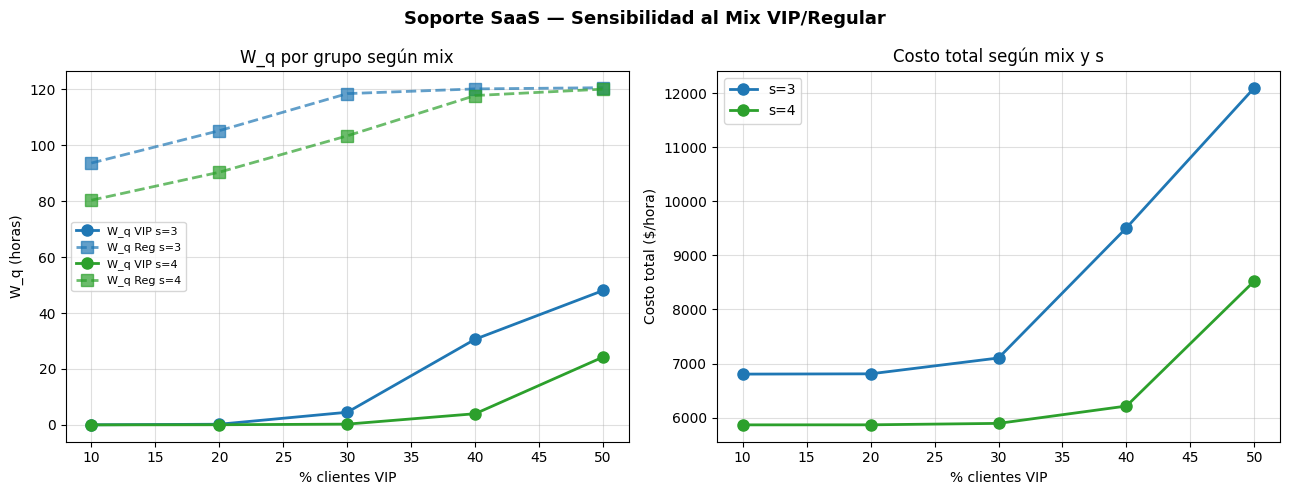

In [29]:
# ── Sensibilidad al mix VIP/Regular ──────────────────────────────────────────
lam_total   = 10
fracs_vip   = [0.10, 0.20, 0.30, 0.40, 0.50]
s_lista     = [3, 4]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Soporte SaaS — Sensibilidad al Mix VIP/Regular",
             fontsize=13, fontweight='bold')

colors_s = ['C0', 'C2']
for j, s_v in enumerate(s_lista):
    Wq_vip_list, Wq_reg_list, costo_list = [], [], []
    for frac in fracs_vip:
        lv = lam_total * frac
        lr = lam_total * (1 - frac)
        r  = simular_prioridad(lv, lr, mu, s_v, n_pasos, n_rep,
                               costo_vip=costo_vip, costo_reg=costo_reg,
                               costo_agente=costo_agente)
        Wq_vip_list.append(r["vip"]["Wq"])
        Wq_reg_list.append(r["reg"]["Wq"])
        costo_list.append(r["costo_total"])

    pct = [int(f*100) for f in fracs_vip]
    axes[0].plot(pct, Wq_vip_list, '-o',  color=colors_s[j], linewidth=2, markersize=8,
                 label=f"W_q VIP s={s_v}")
    axes[0].plot(pct, Wq_reg_list, '--s', color=colors_s[j], linewidth=2, markersize=8,
                 alpha=0.7, label=f"W_q Reg s={s_v}")
    axes[1].plot(pct, costo_list,  '-o',  color=colors_s[j], linewidth=2, markersize=8,
                 label=f"s={s_v}")

axes[0].set_xlabel("% clientes VIP"); axes[0].set_ylabel("W_q (horas)")
axes[0].set_title("W_q por grupo según mix"); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.4)
axes[1].set_xlabel("% clientes VIP"); axes[1].set_ylabel("Costo total ($/hora)")
axes[1].set_title("Costo total según mix y s"); axes[1].legend(); axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


---
# Problema 6 — Procesador de Pagos: Picos de Demanda y Análisis de Riesgo

**s = 4 servidores**, **μ = 3 tx/min**. Demanda variable: normal λ=5, pico λ=15.

$$C = 2 \cdot L_q + 30 \cdot s$$

**Preguntas:** ¿Cuántos servidores escalar en cada pico? ¿Cuál es la probabilidad de que la cola supere un umbral crítico?


In [30]:
# ── Efecto de λ sobre las métricas (s fijo = 4) ──────────────────────────────
mu             = 3
s              = 4
n_pasos        = 200
n_rep          = 600
costo_demora   = 2
costo_servidor = 30

lambdas = [3, 5, 7, 9, 10, 11]

res_lam = []
print(f"Capacidad total: s·μ = {s*mu} tx/min")
print(f"{'λ':>5} {'ρ':>6} {'L_q':>9} {'W_q(min)':>10} {'C_total':>10}")
print("-" * 48)
for lam in lambdas:
    r = simular_mms(lam, mu, s, n_pasos, n_rep,
                    costo_espera=costo_demora, costo_servidor=costo_servidor)
    if r is None:
        print(f"{lam:>5}  ≥1   sistema inestable")
        continue
    res_lam.append(r | {"lam": lam})
    print(f"{lam:>5} {r['rho']:>6.2f} {r['Lq']:>9.3f} {r['Wq']:>10.3f} {r['costo_total']:>10.2f}")


Capacidad total: s·μ = 12 tx/min
    λ      ρ       L_q   W_q(min)    C_total
------------------------------------------------
    3   0.25     0.008      0.003     120.02
    5   0.42     0.073      0.015     120.15
    7   0.58     0.351      0.050     120.70
    9   0.75     1.500      0.167     123.00
   10   0.83     3.112      0.311     126.22
   11   0.92     8.780      0.798     137.56


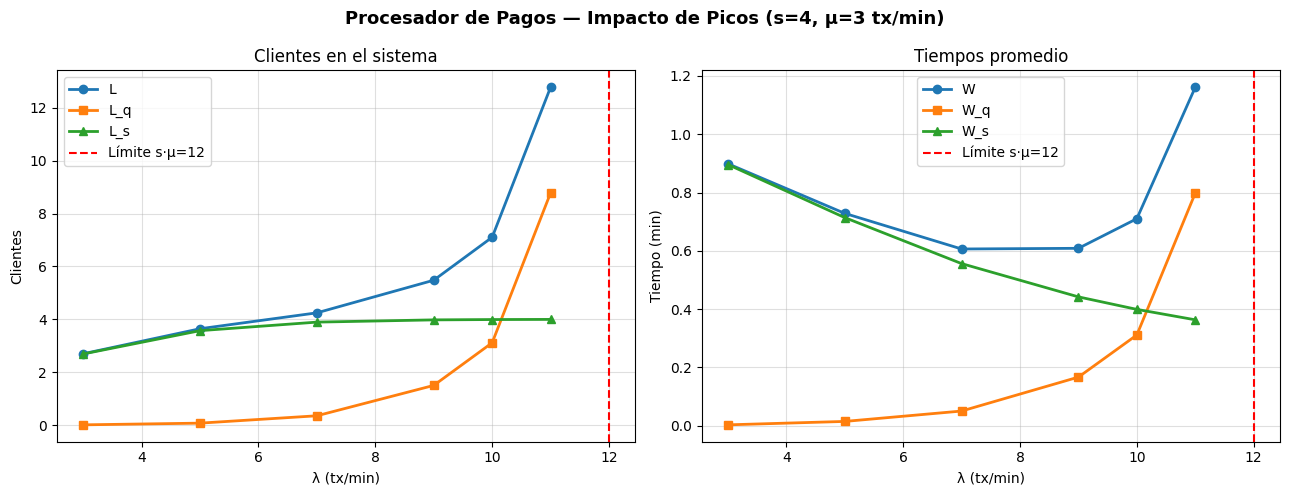


📌 Cuando ρ → 1 las métricas explotan de forma NO LINEAL.
   Los sistemas reales operan con ρ ∈ [0.70, 0.85] para tener margen de seguridad.


In [31]:
# ── Gráficos: métricas vs λ ───────────────────────────────────────────────────
lam_e = [r["lam"] for r in res_lam]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Procesador de Pagos — Impacto de Picos (s=4, μ=3 tx/min)",
             fontsize=13, fontweight='bold')

axes[0].plot(lam_e, [r["L"]  for r in res_lam], '-o', linewidth=2, label="L")
axes[0].plot(lam_e, [r["Lq"] for r in res_lam], '-s', linewidth=2, label="L_q")
axes[0].plot(lam_e, [r["Ls"] for r in res_lam], '-^', linewidth=2, label="L_s")
axes[0].axvline(s * mu, color='red', linestyle='--', label=f"Límite s·μ={s*mu}")
axes[0].set_xlabel("λ (tx/min)"); axes[0].set_ylabel("Clientes")
axes[0].set_title("Clientes en el sistema"); axes[0].legend(); axes[0].grid(True, alpha=0.4)

axes[1].plot(lam_e, [r["W"]  for r in res_lam], '-o', linewidth=2, label="W")
axes[1].plot(lam_e, [r["Wq"] for r in res_lam], '-s', linewidth=2, label="W_q")
axes[1].plot(lam_e, [r["Ws"] for r in res_lam], '-^', linewidth=2, label="W_s")
axes[1].axvline(s * mu, color='red', linestyle='--', label=f"Límite s·μ={s*mu}")
axes[1].set_xlabel("λ (tx/min)"); axes[1].set_ylabel("Tiempo (min)")
axes[1].set_title("Tiempos promedio"); axes[1].legend(); axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print("\n📌 Cuando ρ → 1 las métricas explotan de forma NO LINEAL.")
print("   Los sistemas reales operan con ρ ∈ [0.70, 0.85] para tener margen de seguridad.")


⚠️  SISTEMA INESTABLE: ρ = 1.67 ≥ 1  (λ=10, s=2, μ=3)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.11 ≥ 1  (λ=10, s=3, μ=3)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 2.50 ≥ 1  (λ=15, s=2, μ=3)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.67 ≥ 1  (λ=15, s=3, μ=3)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.25 ≥ 1  (λ=15, s=4, μ=3)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.00 ≥ 1  (λ=15, s=5, μ=3)
    Las métricas no tienen sentido en estado estacionario.


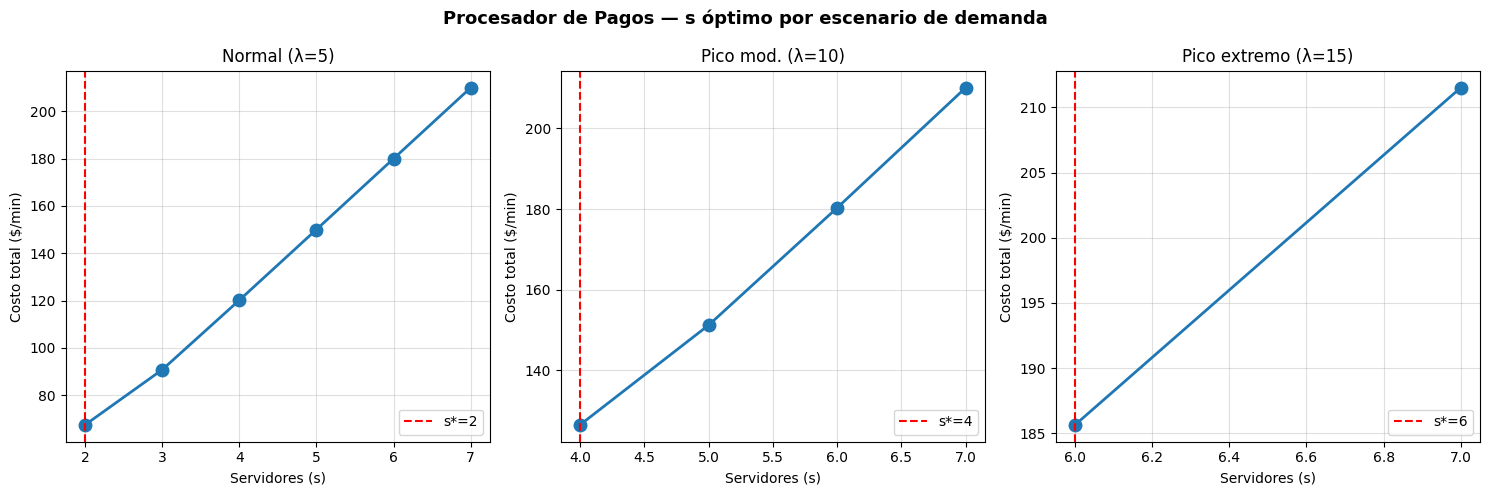

In [32]:
# ── ¿Cuántos servidores escalar para absorber el pico? ───────────────────────
mu             = 3
lam_pico       = 15   # triple de la demanda normal
n_pasos        = 200
n_rep          = 600
costo_demora   = 2
costo_servidor = 30

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
escenarios = {"Normal (λ=5)": 5, "Pico mod. (λ=10)": 10, "Pico extremo (λ=15)": 15}

for ax, (nombre, lam) in zip(axes, escenarios.items()):
    costos_s, s_estables = [], []
    for s in range(2, 8):
        r = simular_mms(lam, mu, s, n_pasos, n_rep,
                        costo_espera=costo_demora, costo_servidor=costo_servidor)
        if r:
            costos_s.append(r["costo_total"])
            s_estables.append(s)
    if costos_s:
        s_opt_v = s_estables[np.argmin(costos_s)]
        ax.plot(s_estables, costos_s, '-o', linewidth=2, markersize=9)
        ax.axvline(s_opt_v, color='red', linestyle='--', label=f"s*={s_opt_v}")
        ax.set_title(f"{nombre}")
        ax.legend()
    ax.set_xlabel("Servidores (s)"); ax.set_ylabel("Costo total ($/min)")
    ax.grid(True, alpha=0.4)

fig.suptitle("Procesador de Pagos — s óptimo por escenario de demanda",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


⚠️  SISTEMA INESTABLE: ρ = 1.08 ≥ 1  (λ=13.0, s=6, μ=2.0)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.25 ≥ 1  (λ=15.0, s=6, μ=2.0)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.42 ≥ 1  (λ=17.0, s=6, μ=2.0)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.00 ≥ 1  (λ=15.0, s=6, μ=2.5)
    Las métricas no tienen sentido en estado estacionario.
⚠️  SISTEMA INESTABLE: ρ = 1.13 ≥ 1  (λ=17.0, s=6, μ=2.5)
    Las métricas no tienen sentido en estado estacionario.


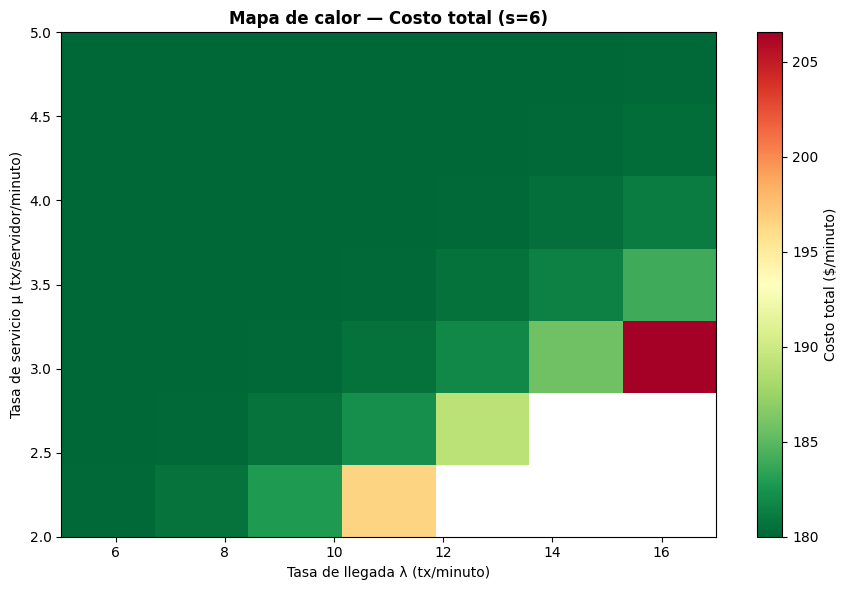


📌 Verde = bajo costo (sistema holgado)  |  Rojo = alto costo o inestable (ρ → 1)
   Las zonas blancas (nan) son sistemas inestables que la simulación descarta.


In [33]:
# ── Mapa de calor: sensibilidad bidimensional λ × μ ──────────────────────────
s              = 6
n_pasos        = 150
n_rep          = 300
costo_demora   = 2
costo_servidor = 30

lam_vals = np.linspace(5, 17, 7)
mu_vals  = np.linspace(2,  5, 7)
grilla   = np.full((len(mu_vals), len(lam_vals)), np.nan)

for i, mu_v in enumerate(mu_vals):
    for j, lam_v in enumerate(lam_vals):
        r = simular_mms(lam_v, mu_v, s, n_pasos, n_rep,
                        costo_espera=costo_demora, costo_servidor=costo_servidor)
        if r:
            grilla[i, j] = r["costo_total"]

plt.figure(figsize=(9, 6))
im = plt.imshow(grilla, origin='lower', aspect='auto',
                extent=[lam_vals[0], lam_vals[-1], mu_vals[0], mu_vals[-1]],
                cmap='RdYlGn_r')
plt.colorbar(im, label="Costo total ($/minuto)")
plt.xlabel("Tasa de llegada λ (tx/minuto)")
plt.ylabel("Tasa de servicio μ (tx/servidor/minuto)")
plt.title(f"Mapa de calor — Costo total (s={s})", fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📌 Verde = bajo costo (sistema holgado)  |  Rojo = alto costo o inestable (ρ → 1)")
print("   Las zonas blancas (nan) son sistemas inestables que la simulación descarta.")


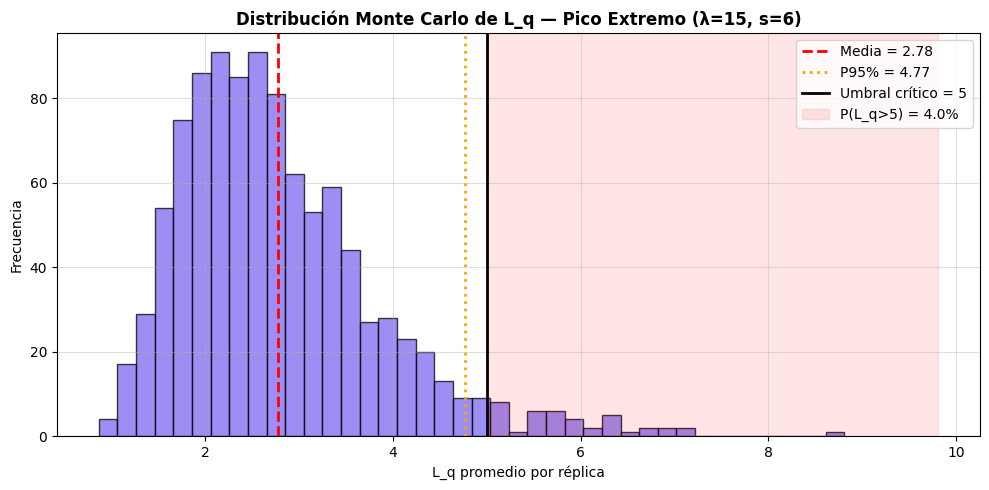

Media:           2.779 tx
Desv. estándar:  1.064 tx
Percentil  5%:   1.468 tx
Percentil 95%:   4.766 tx
P(L_q > 5):    4.0%

📌 Esta probabilidad puede usarse como KPI para decisiones de escalamiento:
   si P(L_q>5) supera un umbral aceptable, se activa el auto-scaling.


In [34]:
# ── Distribución de riesgo: P(L_q > umbral) en el pico extremo ───────────────
lam     = 15
mu      = 3
s       = 6
n_pasos = 200
n_rep   = 1000
burn    = n_pasos // 5
umbral  = 5    # más de 5 tx en cola = "alerta crítica"

Lq_por_replica = []
for _ in range(n_rep):
    cola = 0
    hist = []
    for _ in range(n_pasos):
        cola += np.random.poisson(lam)
        cola -= min(cola, np.random.poisson(s * mu))
        hist.append(cola)
    Lq_por_replica.append(np.mean(hist[burn:]))

Lq_arr      = np.array(Lq_por_replica)
prob_umbral = (Lq_arr > umbral).mean()

plt.figure(figsize=(10, 5))
_, bins, _ = plt.hist(Lq_arr, bins=40, color='mediumslateblue', edgecolor='k', alpha=0.75)
plt.axvline(Lq_arr.mean(),           color='red',    linestyle='--', linewidth=2,
            label=f"Media = {Lq_arr.mean():.2f}")
plt.axvline(np.percentile(Lq_arr, 95), color='orange', linestyle=':', linewidth=2,
            label=f"P95% = {np.percentile(Lq_arr, 95):.2f}")
plt.axvline(umbral, color='black', linestyle='-', linewidth=2,
            label=f"Umbral crítico = {umbral}")
plt.axvspan(umbral, Lq_arr.max() + 1, color='red', alpha=0.1,
            label=f"P(L_q>{umbral}) = {prob_umbral:.1%}")
plt.xlabel("L_q promedio por réplica"); plt.ylabel("Frecuencia")
plt.title(f"Distribución Monte Carlo de L_q — Pico Extremo (λ={lam}, s={s})",
          fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.4); plt.tight_layout()
plt.show()

print(f"Media:           {Lq_arr.mean():.3f} tx")
print(f"Desv. estándar:  {Lq_arr.std():.3f} tx")
print(f"Percentil  5%:   {np.percentile(Lq_arr,  5):.3f} tx")
print(f"Percentil 95%:   {np.percentile(Lq_arr, 95):.3f} tx")
print(f"P(L_q > {umbral}):    {prob_umbral:.1%}")
print("\n📌 Esta probabilidad puede usarse como KPI para decisiones de escalamiento:")
print(f"   si P(L_q>{umbral}) supera un umbral aceptable, se activa el auto-scaling.")


---
# Resumen Ejecutivo

## Resultados por problema

| Problema | Modelo | s* / K* | Insight de negocio |
|----------|--------|---------|-------------------|
| Banco | M/M/s | Ver tabla | Costo mínimo equilibra espera y personal |
| Soporte técnico | M/M/s/K | Ver tabla | Agregar K limita espera pero genera rechazos |
| Call center | M/M/s | Ver tabla | Sensibilidad a λ es no lineal cerca del límite |
| Supermercado | M/M/s/K | Ver tabla | K óptimo balancea rechazos vs. espera |
| Soporte SaaS | Prioridades | — | Prioridades tienen valor económico cuantificable |
| Pagos | M/M/s | Ver tabla | El riesgo se puede expresar como P(L_q > umbral) |

## Takeaways de negocios

1. **Operar cerca del límite (ρ → 1) es costoso y riesgoso.** El costo crece no linealmente. Los sistemas reales se diseñan con ρ ∈ [0.70, 0.85].
2. **El primer servidor extra tiene el mayor impacto.** El cuarto o quinto tiene rendimiento marginal decreciente.
3. **Invertir en μ (capacitación, automatización) es más estabilizador** que solo agregar servidores: desplaza la curva hacia abajo en toda la región.
4. **Las prioridades redistribuyen el costo entre segmentos** pero no lo eliminan. Su valor económico depende del diferencial de costo de churn entre segmentos.
5. **Monte Carlo da la distribución del riesgo**, no solo el promedio. La diferencia entre P50 y P95 del costo es lo que necesita un gerente para decidir cuánto invertir en resiliencia.
